# 01 - Setup & Data Download
**Goals:** check GPU, set seeds, create folders, download both datasets, sanity-check them.

- **Dataset A (classification):** Kaggle Brain Tumor MRI (glioma / meningioma / pituitary / no tumor)
- **Dataset B (segmentation):** Figshare brain tumor dataset (3,064 slices with tumor masks)

In [1]:
import os
import random
import json
import zipfile
import subprocess
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import h5py
import matplotlib.pyplot as plt
from PIL import Image
import torch

print("Imports OK")

Imports OK


In [2]:
SEED = 42

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch :", torch.__version__)
print("Device  :", DEVICE)
if DEVICE.type == "cuda":
    print("GPU     :", torch.cuda.get_device_name(0))
    print("VRAM    : %.1f GB" % (torch.cuda.get_device_properties(0).total_memory / 1e9))
else:
    print("WARNING: CUDA not available. Check your PyTorch install.")

PyTorch : 2.6.0+cu124
Device  : cuda
GPU     : NVIDIA A100 80GB PCIe
VRAM    : 85.0 GB


In [3]:
ROOT = Path.cwd()
DATA_DIR = ROOT / "data"
CLS_DIR = DATA_DIR / "classification"        # Dataset A
SEG_RAW_DIR = DATA_DIR / "segmentation_raw"  # Dataset B (.mat files)
OUT_DIR = ROOT / "outputs"
MODEL_DIR = OUT_DIR / "models"
FIG_DIR = OUT_DIR / "figures"

for d in [CLS_DIR, SEG_RAW_DIR, MODEL_DIR, FIG_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print("Project root:", ROOT)
for d in [CLS_DIR, SEG_RAW_DIR, MODEL_DIR, FIG_DIR]:
    print(" -", d.relative_to(ROOT))

Project root: /nmhs2/hari/work/UAV/Projects/BrainSight/notebook
 - data/classification
 - data/segmentation_raw
 - outputs/models
 - outputs/figures


## Dataset A: Kaggle Brain Tumor MRI
Needs a Kaggle API token:
1. Kaggle > Settings > API > **Create New Token** (downloads `kaggle.json`)
2. Place it at `~/.kaggle/kaggle.json` (Windows: `C:\Users\<you>\.kaggle\kaggle.json`)

If you'd rather skip the API, download the zip manually from
https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset
and extract it into `data/classification/`.

In [4]:
CLASSES = ["glioma", "meningioma", "notumor", "pituitary"]
IMG_EXTS = {".jpg", ".jpeg", ".png"}

rows = []
for split in ["Training", "Testing"]:
    for cls in CLASSES:
        folder = CLS_DIR / split / cls
        n = len([p for p in folder.glob("*") if p.suffix.lower() in IMG_EXTS])
        rows.append({"split": split, "class": cls, "count": n})

df_counts = pd.DataFrame(rows).pivot(index="class", columns="split", values="count")
df_counts["Total"] = df_counts.sum(axis=1)
print(df_counts)
print("\nGrand total:", int(df_counts["Total"].sum()))

split       Testing  Training  Total
class                               
glioma          400      1400   1800
meningioma      400      1400   1800
notumor         400      1400   1800
pituitary       400      1400   1800

Grand total: 7200


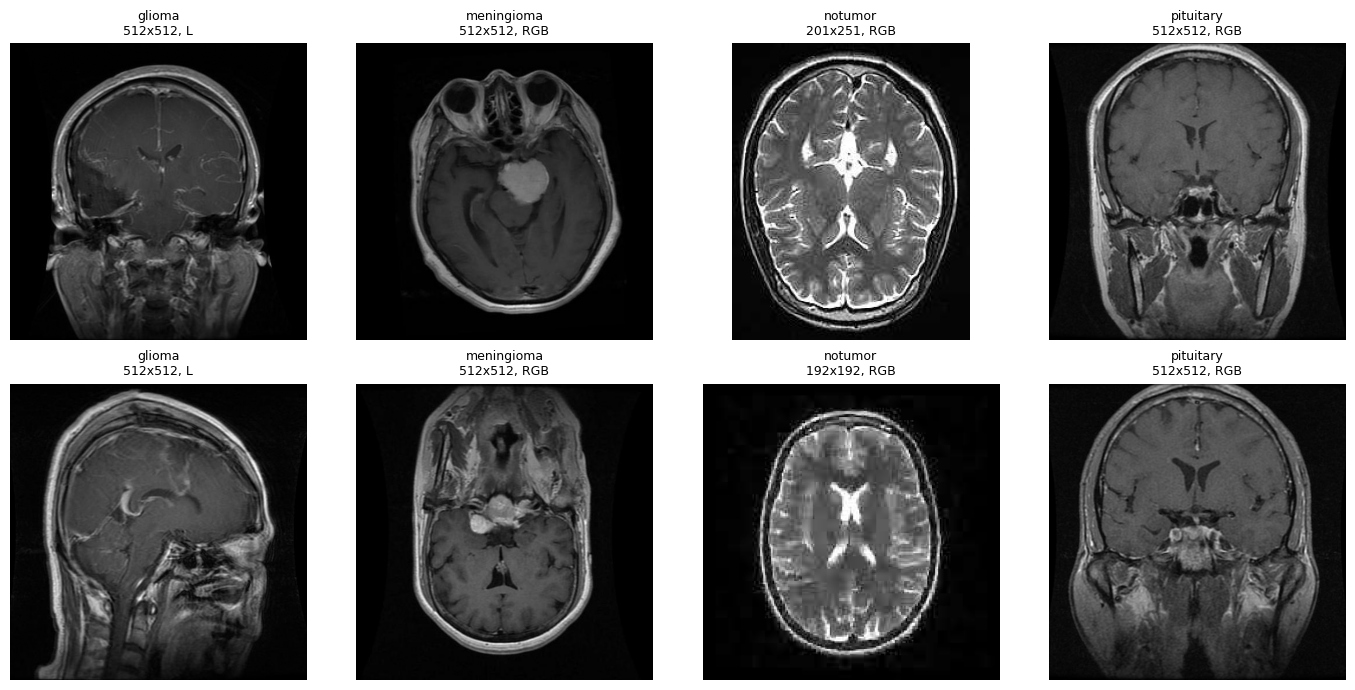

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for j, cls in enumerate(CLASSES):
    files = sorted((CLS_DIR / "Training" / cls).glob("*"))[:2]
    for i, f in enumerate(files):
        img = Image.open(f)
        axes[i, j].imshow(img, cmap="gray")
        axes[i, j].set_title(f"{cls}\n{img.size[0]}x{img.size[1]}, {img.mode}", fontsize=9)
        axes[i, j].axis("off")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_dataset_A_samples.png", dpi=120)
plt.show()

## Dataset B: Figshare brain tumor dataset (with masks)
3,064 T1-weighted contrast-enhanced slices from 233 patients. Each `.mat` file contains:
`label` (1 = meningioma, 2 = glioma, 3 = pituitary), `image`, `tumorMask`, `tumorBorder`, `PID`.

The download is ~900 MB and ships as nested zips. If the automatic download fails,
get it manually from https://figshare.com/articles/dataset/brain_tumor_dataset/1512427
and put the zip files in `data/segmentation_raw/`.

In [8]:
def extract_all(folder: Path):
    """Keep extracting zips until none remain."""
    while True:
        zips = list(folder.rglob("*.zip"))
        if not zips:
            break
        for z in zips:
            print("Extracting", z.name)
            with zipfile.ZipFile(z) as zf:
                zf.extractall(z.parent)
            z.unlink()

if not list(SEG_RAW_DIR.rglob("*.mat")):
    extract_all(SEG_RAW_DIR)

mat_files = sorted(SEG_RAW_DIR.rglob("*.mat"), key=lambda p: int(p.stem) if p.stem.isdigit() else 0)
print("Total .mat files:", len(mat_files))
assert len(mat_files) == 3064, "Expected 3064 files, check the download/extraction."

Total .mat files: 3064


In [9]:
def load_mat(path):
    with h5py.File(path, "r") as f:
        d = f["cjdata"]
        image = np.array(d["image"]).T            # MATLAB is column-major, so transpose
        mask = np.array(d["tumorMask"]).T
        label = int(np.array(d["label"]).squeeze())
        pid = "".join(chr(c) for c in np.array(d["PID"]).squeeze())
    return image, mask, label, pid

LABEL_MAP = {1: "meningioma", 2: "glioma", 3: "pituitary"}

img, msk, lab, pid = load_mat(mat_files[0])
print("File     :", mat_files[0].name)
print("Image    :", img.shape, img.dtype, "| range", img.min(), "-", img.max())
print("Mask     :", msk.shape, msk.dtype, "| unique", np.unique(msk))
print("Label    :", lab, "->", LABEL_MAP[lab])
print("Patient  :", pid)

File     : 1.mat
Image    : (512, 512) int16 | range 0 - 3366
Mask     : (512, 512) uint8 | unique [0 1]
Label    : 1 -> meningioma
Patient  : 100360


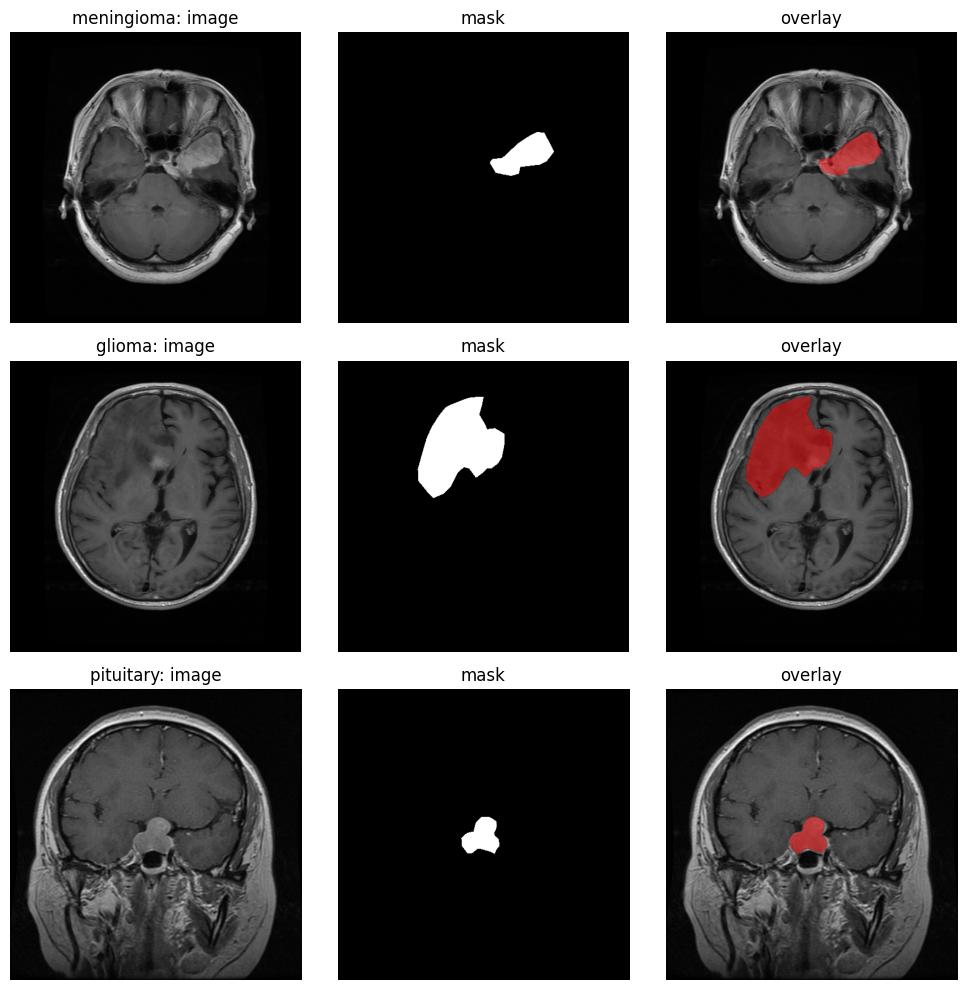

In [10]:
fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for row, lab_id in enumerate([1, 2, 3]):
    # find 1 sample for each class from the first 300 files
    for p in mat_files[:300]:
        im, mk, lb, _ = load_mat(p)
        if lb == lab_id:
            break
    axes[row, 0].imshow(im, cmap="gray");  axes[row, 0].set_title(f"{LABEL_MAP[lab_id]}: image")
    axes[row, 1].imshow(mk, cmap="gray");  axes[row, 1].set_title("mask")
    axes[row, 2].imshow(im, cmap="gray");  axes[row, 2].imshow(np.ma.masked_where(mk == 0, mk), cmap="autumn", alpha=0.5)
    axes[row, 2].set_title("overlay")
    for a in axes[row]: a.axis("off")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_dataset_B_samples.png", dpi=120)
plt.show()

In [11]:
records = []
for p in mat_files:
    with h5py.File(p, "r") as f:
        d = f["cjdata"]
        label = int(np.array(d["label"]).squeeze())
        pid = "".join(chr(c) for c in np.array(d["PID"]).squeeze())
        h, w = np.array(d["image"]).shape
        tumor_px = int(np.array(d["tumorMask"]).sum())
    records.append({"file": p.name, "path": str(p), "patient_id": pid,
                    "label": label, "class": LABEL_MAP[label],
                    "height": h, "width": w, "tumor_pixels": tumor_px})

df_seg = pd.DataFrame(records)
df_seg.to_csv(DATA_DIR / "segmentation_metadata.csv", index=False)

print(df_seg["class"].value_counts())
print("\nUnique patients:", df_seg["patient_id"].nunique())
print("Image sizes    :", df_seg[["height", "width"]].drop_duplicates().values.tolist())
df_seg.head()

class
glioma        1426
pituitary      930
meningioma     708
Name: count, dtype: int64

Unique patients: 233
Image sizes    : [[512, 512], [256, 256]]


,file,path,patient_id,label,class,height,width,tumor_pixels
0,1.mat,/nmhs2/hari/work/UAV/Projects/BrainSight/noteb...,100360,1,meningioma,512,512,4569
1,2.mat,/nmhs2/hari/work/UAV/Projects/BrainSight/noteb...,100360,1,meningioma,512,512,8630
2,3.mat,/nmhs2/hari/work/UAV/Projects/BrainSight/noteb...,100360,1,meningioma,512,512,10511
3,4.mat,/nmhs2/hari/work/UAV/Projects/BrainSight/noteb...,100360,1,meningioma,512,512,8897
4,5.mat,/nmhs2/hari/work/UAV/Projects/BrainSight/noteb...,100360,1,meningioma,512,512,11250


In [12]:
config = {
    "seed": SEED,
    "classes": CLASSES,
    "seg_label_map": LABEL_MAP,
    "paths": {
        "classification": str(CLS_DIR),
        "segmentation_raw": str(SEG_RAW_DIR),
        "segmentation_metadata": str(DATA_DIR / "segmentation_metadata.csv"),
        "models": str(MODEL_DIR),
        "figures": str(FIG_DIR),
    },
}
with open(ROOT / "config.json", "w") as f:
    json.dump(config, f, indent=2)
print("Saved config.json")

Saved config.json
